# Normal stresses, the yield invariant and elastoviscoplasticity

Push a yield-stress gel in a cone–plate rheometer and the instrument records not only a torque but also a normal force that tries to separate the plates. The Herschel–Bulkley (HB) law cannot produce that force: as an isotropic, inelastic law it predicts zero normal-stress differences in simple shear. De Cagny et al. (2019) measured both normal-stress differences of three HB materials and found $N_1>0$ and $N_2<0$, both growing as the square of the shear stress. This notebook asks three questions with their published fits: why the isotropic law gives none, whether the measured normal stresses shift the von Mises yield criterion, and what an elastoviscoplastic (EVP) extension, the Saramito model, predicts.

### Where this is in the review
* **Supplementary Note S3**, "Normal stresses and the yield invariant": the fit coefficients of de Cagny et al. (2019), **Table SII**; the stress magnitude with normal stresses, **Eq. (S5)**; **Fig. S2** (script `scripts/figS2_normal_stress.py`).
* **Supplementary Note S4**, "Steady simple shear of the Saramito HB model": **Eqs. (S6)–(S11)**.
* Article **Sec. VIII C**, "Elastoviscoplasticity and the normal-stress test": the Saramito model, **Eq. (32)**, and its steady shear solution, **Eq. (33)**; the tensorial law and von Mises criterion, **Secs. IV A–B, Eq. (4)**; **Sec. IX** (normal stresses lie outside the baseline model) and row D of **Table XII**; the Saramito HB row of **Table X**.
* Data: `data/normal_stress_reconstruction.json`, `data/normal_stress_curves.csv`, and the plotted series in `data/figure_data/figS2_normal_stress.csv`. These are reconstructions from the published fit coefficients, not measured points.

### Learning objectives
1. Show from the tensorial law that any isotropic generalized Newtonian fluid, HB included, has $N_1=N_2=0$ in steady simple shear.
2. Compute the von Mises stress magnitude $\sigma_d$ in simple shear with normal-stress differences, Eq. (S5), and use it to judge whether normal stresses shift yielding.
3. Derive and verify the steady simple-shear solution of the Saramito model, and see how its flow curve departs from HB at $O((\sigma/G)^2)$.
4. Use the measured ratio $\psi_2/\psi_1$ to test the upper-convected Saramito model without fitting anything.

In [1]:
# Standard set-up used by every notebook in this folder.
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the repository root whether the notebook runs from notebooks/ or from the root.
ROOT = Path.cwd().resolve()
ROOT = ROOT.parent if (ROOT.parent / "data").exists() and not (ROOT / "data").exists() else ROOT
DATA = ROOT / "data"
FIGDATA = DATA / "figure_data"
sys.path.insert(0, str(ROOT / "scripts"))
sys.dont_write_bytecode = True      # do not leave compiled files in scripts/

# Plot style and palette of the article. hbstyle also defines save(), which rewrites the
# published figures and data: it is deliberately NOT imported or called here.
from hbstyle import C
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 110})


def figure_series(df, panel, series):
    """x and y of one plotted series in a data/figure_data/<figure>.csv table."""
    s = df[(df["panel"] == panel) & (df["series"] == series)].sort_values("index")
    if s.empty:
        raise KeyError(f"no series {series!r} in panel {panel!r}")
    return s["x"].to_numpy(float), s["y"].to_numpy(float)

import json
from scipy.optimize import brentq, fsolve
from scipy.integrate import solve_ivp

## 1. Why the isotropic HB law has no normal-stress differences

The tensorial HB law (article Eq. 4; Hohenemser and Prager, 1932; Oldroyd, 1947) reads
$$\boldsymbol\tau=\left(\frac{\sigma_y}{\dot\gamma}+K\dot\gamma^{\,n-1}\right)2\mathbf D\quad(\sigma>\sigma_y),\qquad \mathbf D=\mathbf 0\quad(\sigma\le\sigma_y),$$
with $\mathbf D=\tfrac12(\nabla\mathbf u+\nabla\mathbf u^{T})$, $\dot\gamma=\sqrt{2\mathbf D:\mathbf D}$ and $\sigma=\sqrt{\tfrac12\boldsymbol\tau:\boldsymbol\tau}$. The extra stress is a scalar times $\mathbf D$. In steady simple shear, $\mathbf u=(\dot\gamma y,0,0)$, the only nonzero components of $\mathbf D$ are $D_{xy}=D_{yx}=\dot\gamma/2$: its diagonal is zero, so the diagonal of $\boldsymbol\tau$ is zero too, and
$$N_1=\tau_{xx}-\tau_{yy}=0,\qquad N_2=\tau_{yy}-\tau_{zz}=0.$$
The argument uses only the form "scalar viscosity times $\mathbf D$", so it holds for every isotropic generalized Newtonian law, with or without yield stress. Let us check it numerically, together with the identities $\dot\gamma=\sqrt{2\mathbf D:\mathbf D}$ and $\sigma=|\tau_{xy}|$.

In [2]:
sigma_y, K, n = 10.0, 2.0, 0.5            # illustrative HB parameters (those of Sec. VIII C)
gd = 5.0                                   # shear rate, 1/s

grad_u = np.zeros((3, 3)); grad_u[0, 1] = gd           # (grad u)_ij = du_i/dx_j for u = (gd*y, 0, 0)
D = 0.5 * (grad_u + grad_u.T)
gd_mag = np.sqrt(2 * np.sum(D * D))
tau = (sigma_y / gd_mag + K * gd_mag ** (n - 1)) * 2 * D
sigma_mag = np.sqrt(0.5 * np.sum(tau * tau))

print("D =\n", D)
print(f"sqrt(2 D:D) = {gd_mag:g} (imposed rate {gd:g})")
print(f"tau_xy = {tau[0, 1]:.4f} Pa = sigma_y + K gd^n = {sigma_y + K * gd ** n:.4f} Pa;  sigma = sqrt(tau:tau/2) = {sigma_mag:.4f} Pa")
print(f"N1 = {tau[0, 0] - tau[1, 1]:g} Pa, N2 = {tau[1, 1] - tau[2, 2]:g} Pa")
assert np.isclose(gd_mag, gd) and np.isclose(sigma_mag, tau[0, 1]) and np.allclose(np.diag(tau), 0)

D =
 [[0.  2.5 0. ]
 [2.5 0.  0. ]
 [0.  0.  0. ]]
sqrt(2 D:D) = 5 (imposed rate 5)
tau_xy = 14.4721 Pa = sigma_y + K gd^n = 14.4721 Pa;  sigma = sqrt(tau:tau/2) = 14.4721 Pa
N1 = 0 Pa, N2 = 0 Pa


## 2. The yield invariant when normal stresses are present

Suppose that a material in simple shear carries, besides the shear stress $\sigma=\tau_{xy}$, normal-stress differences $N_1$ and $N_2$. The pressure is arbitrary in an incompressible material, so only the **deviatoric** part $\boldsymbol\tau_d=\boldsymbol\tau-\tfrac13({\rm tr}\,\boldsymbol\tau)\mathbf I$ enters a von Mises criterion. Its diagonal components are
$$\tfrac13(2N_1+N_2),\qquad \tfrac13(N_2-N_1),\qquad -\tfrac13(N_1+2N_2),$$
and the off-diagonal component is $\sigma$. The stress magnitude used in the von Mises criterion is then (Note S3, **Eq. (S5)**)
$$\sigma_d^2\equiv\tfrac12\boldsymbol\tau_d:\boldsymbol\tau_d=\sigma^2+\frac{N_1^2+N_1N_2+N_2^2}{3}.$$
Without normal stresses $\sigma_d=\sigma$, and yielding in shear happens at $\sigma=\sigma_y$. With them, $\sigma_d>\sigma$, so the shear stress at which $\sigma_d$ reaches the yield value is lower. We verify Eq. (S5) for random values, including an arbitrary isotropic pressure.

In [3]:
def sigma_d_eq_S5(s, N1, N2):
    """Eq. (S5): von Mises stress magnitude in simple shear with normal-stress differences."""
    return np.sqrt(s * s + (N1 * N1 + N1 * N2 + N2 * N2) / 3)

rng = np.random.default_rng(1)
for _ in range(5):
    s, N1, N2, p = rng.normal(0, 50, 4)
    T = np.diag([0.0, -N1, -N1 - N2]) + p * np.eye(3)       # tau_xx - tau_yy = N1, tau_yy - tau_zz = N2
    T[0, 1] = T[1, 0] = s
    Td = T - np.trace(T) / 3 * np.eye(3)
    assert np.allclose(np.diag(Td), [(2 * N1 + N2) / 3, (N2 - N1) / 3, -(N1 + 2 * N2) / 3])
    assert np.isclose(np.sqrt(0.5 * np.sum(Td * Td)), sigma_d_eq_S5(s, N1, N2))
print("Deviator components and Eq. (S5) verified for 5 random stress states (any pressure).")

Deviator components and Eq. (S5) verified for 5 random stress states (any pressure).


## 3. The measurements of de Cagny et al. (2019)

De Cagny and co-workers measured both normal-stress differences of an emulsion, a hair gel and a Carbopol gel whose shear flow curves follow HB, using rough cone–plate and plate–plate geometries with control of instrument drift and of normal force trapped near yield. Their data follow
$$N_i=\psi_i\,\sigma^2,$$
where $\sigma$ is the shear stress and $\psi_i$ (Pa$^{-1}$) are **stress-based** coefficients, not the usual rate-based normal-stress coefficients $\Psi_i=N_i/\dot\gamma^2$. Table SII lists the published coefficients; we load them from the stored reconstruction file.

In [4]:
recon = json.loads((DATA / "normal_stress_reconstruction.json").read_text())
print(recon["source"], "| doi:", recon["doi"])
mat = pd.DataFrame(recon["materials"]).set_index("material")
tableSII = mat[["sigma_y_Pa", "K_Pa_s_n", "n", "psi1_Pa_inv", "psi2_Pa_inv"]].copy()
tableSII["1e3 psi1"] = 1e3 * tableSII.pop("psi1_Pa_inv")
tableSII["1e3 psi2"] = 1e3 * tableSII.pop("psi2_Pa_inv")
tableSII["psi2/psi1"] = tableSII["1e3 psi2"] / tableSII["1e3 psi1"]
print(tableSII.round(3).to_string())

de Cagny et al., J. Rheol. 63, 285 (2019), Table 1 and SI Table A | doi: 10.1122/1.5063796
          sigma_y_Pa  K_Pa_s_n     n  1e3 psi1  1e3 psi2  psi2/psi1
material                                                           
Emulsion       53.56     27.00  0.42      3.19     -2.32     -0.727
Hair gel       56.50     18.00  0.44      3.22     -1.57     -0.488
Carbopol       65.51     28.13  0.40      2.99     -2.58     -0.863


### How large are the normal stresses at yield, and do they shift the yield criterion?
At the HB intercept $\sigma=\sigma_y$ we evaluate $N_1$, $N_2$, the ratio $N_1/\sigma$ and the relative increase of the stress magnitude, $100(\sigma_d/\sigma-1)$.

In [5]:
rows = []
for name, m in mat.iterrows():
    sy, p1, p2 = m["sigma_y_Pa"], m["psi1_Pa_inv"], m["psi2_Pa_inv"]
    N1, N2 = p1 * sy**2, p2 * sy**2
    inc = 100 * (sigma_d_eq_S5(sy, N1, N2) / sy - 1)
    inc100 = 100 * (sigma_d_eq_S5(100, p1 * 1e4, p2 * 1e4) / 100 - 1)
    inc300 = 100 * (sigma_d_eq_S5(300, p1 * 9e4, p2 * 9e4) / 300 - 1)
    rows.append({"material": name, "N1 at sigma_y (Pa)": N1, "N2 at sigma_y (Pa)": N2, "N1/sigma": N1 / sy,
                 "increase at sigma_y (%)": inc, "at 100 Pa (%)": inc100, "at 300 Pa (%)": inc300})
    # compare with the values stored by scripts/figS2_normal_stress.py
    assert np.isclose(N1, m["normal_N1_at_HB_intercept_Pa"]) and np.isclose(inc, m["equivalent_stress_increment_at_intercept_percent"])
at_yield = pd.DataFrame(rows).set_index("material")
print(at_yield.round(3).to_string())

          N1 at sigma_y (Pa)  N2 at sigma_y (Pa)  N1/sigma  increase at sigma_y (%)  at 100 Pa (%)  at 300 Pa (%)
material                                                                                                         
Emulsion               9.151              -6.655     0.171                    0.389          1.350         11.568
Hair gel              10.279              -5.012     0.182                    0.413          1.288         11.056
Carbopol              12.832             -11.072     0.196                    0.562          1.305         11.197


These are the numbers of Note S3: at the yield stress $N_1=9.2$, 10.3 and 12.8 Pa, about a fifth of $\sigma_y$, yet $\sigma_d$ exceeds $\sigma$ by only 0.39%, 0.41% and 0.56%. The reason is the square in Eq. (S5): a normal stress of 20% of the shear stress adds about $0.2^2/3\approx1.3\%$ to $\sigma_d^2$, i.e. about 0.7% to $\sigma_d$, and the negative $N_2$ reduces even that. This recovers the conclusion of de Cagny et al. that normal stresses barely shift the onset invariant. Because $N_i\propto\sigma^2$, however, the increase grows like $\sigma^2$: about 1.3% at 100 Pa and 11–12% at 300 Pa. Normal stresses can therefore be negligible for the onset criterion and still dominate a normal-force reading or a free-surface shape at the same stress.

## 4. Reproducing Fig. S2 and checking it against the figure data

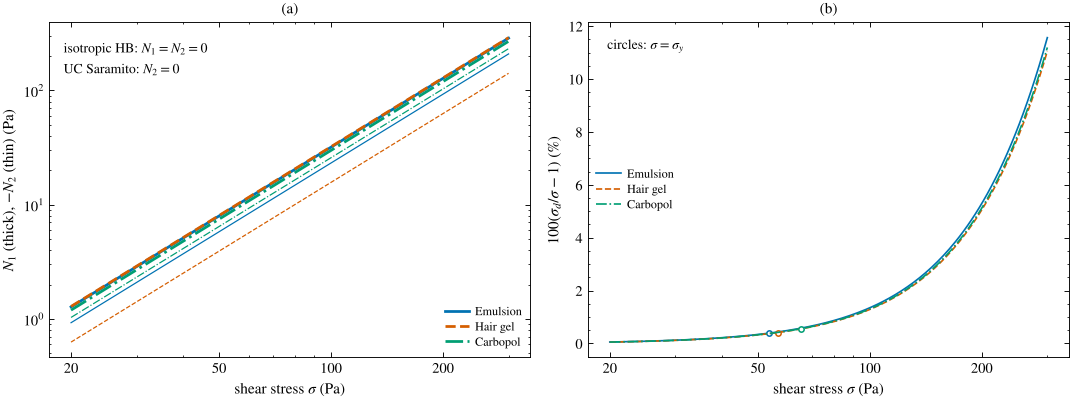

In [6]:
s = np.geomspace(20, 300, 220)                     # stress grid of the script
styles = {"Emulsion": (C["blue"], "-"), "Hair gel": (C["red"], "--"), "Carbopol": (C["green"], "-.")}
curves = {}
fig, ax = plt.subplots(1, 2, figsize=(10, 3.9))
for name, m in mat.iterrows():
    col, ls = styles[name]
    N1, N2 = m["psi1_Pa_inv"] * s**2, m["psi2_Pa_inv"] * s**2
    inc = 100 * (sigma_d_eq_S5(s, N1, N2) / s - 1)
    curves[name] = (N1, N2, inc)
    ax[0].loglog(s, N1, color=col, ls=ls, lw=1.8, label=f"{name}")
    ax[0].loglog(s, -N2, color=col, ls=ls, lw=0.8)
    ax[1].semilogx(s, inc, color=col, ls=ls, label=name)
    ax[1].plot(m["sigma_y_Pa"], at_yield.loc[name, "increase at sigma_y (%)"], "o", color=col, mfc="white")
ax[0].text(0.03, 0.95, "isotropic HB: $N_1=N_2=0$\nUC Saramito: $N_2=0$", transform=ax[0].transAxes, va="top", fontsize=9)
ax[0].set(xlabel=r"shear stress $\sigma$ (Pa)", ylabel=r"$N_1$ (thick), $-N_2$ (thin) (Pa)", title="(a)")
ax[1].text(0.04, 0.95, r"circles: $\sigma=\sigma_y$", transform=ax[1].transAxes, va="top", fontsize=9)
ax[1].set(xlabel=r"shear stress $\sigma$ (Pa)", ylabel=r"$100(\sigma_d/\sigma-1)$ (%)", title="(b)")
from matplotlib.ticker import NullFormatter
for a in ax:
    a.xaxis.set_minor_formatter(NullFormatter())
    a.set_xticks([20, 50, 100, 200]); a.set_xticklabels(["20", "50", "100", "200"])
ax[0].legend(loc="lower right", fontsize=8); ax[1].legend(loc="center left", fontsize=8)
fig.tight_layout(); plt.show()

In [7]:
fdS2 = pd.read_csv(FIGDATA / "figS2_normal_stress.csv", comment="#")
stored_curves = pd.read_csv(DATA / "normal_stress_curves.csv")
RTOL = 1e-8
tags = {"Emulsion": "emulsion", "Hair gel": "hairgel", "Carbopol": "carbopol"}
for name, (N1, N2, inc) in curves.items():
    x, y = figure_series(fdS2, "(a)", f"{name}: N1 (thick)")
    assert np.allclose(x, s, rtol=RTOL) and np.allclose(y, N1, rtol=RTOL)
    x, y = figure_series(fdS2, "(a)", f"{name}: -N2 (thin)")
    assert np.allclose(y, -N2, rtol=RTOL)
    x, y = figure_series(fdS2, "(b)", name)
    assert np.allclose(y, inc, rtol=RTOL)
    x, y = figure_series(fdS2, "(b)", f"{name}: value at sigma = sigma_y")
    assert np.allclose([x[0], y[0]], [mat.loc[name, "sigma_y_Pa"], at_yield.loc[name, "increase at sigma_y (%)"]], rtol=RTOL)
    t = tags[name]
    assert np.allclose(stored_curves[f"{t}_N1_Pa"], N1, rtol=1e-12) and np.allclose(stored_curves[f"{t}_eq_increment_percent"], inc, rtol=1e-12)
assert np.allclose(stored_curves["shear_Pa"], s, rtol=1e-12)
print("Fig. S2 check passed: 9 curves and 3 yield-point markers agree with figS2_normal_stress.csv "
      f"(relative tolerance {RTOL:g}) and with data/normal_stress_curves.csv.")

Fig. S2 check passed: 9 curves and 3 yield-point markers agree with figS2_normal_stress.csv (relative tolerance 1e-08) and with data/normal_stress_curves.csv.


## 5. An elastoviscoplastic extension: the Saramito model

Real yield-stress materials deform reversibly below yield, overshoot on start-up and recoil when flow stops; the HB law stores no elastic energy and can do none of this. Saramito (2007, 2009) adds an evolving elastic stress with a plastic relaxation rate. Without solvent the HB-based model is (article **Eq. 32**)
$$\frac1G\overset{\triangledown}{\boldsymbol\tau}+\alpha(\sigma_d)\,\boldsymbol\tau=2\mathbf D,\qquad \alpha(\sigma_d)=\frac{1}{\sigma_d}\left[\frac{(\sigma_d-\sigma_y)_+}{K}\right]^{1/n},$$
where $G$ is the elastic modulus, $\sigma_d=\sqrt{\tfrac12\boldsymbol\tau_d:\boldsymbol\tau_d}$ is the magnitude of the deviatoric stress, $(x)_+=\max(x,0)$, and the upper-convected derivative is $\overset{\triangledown}{\boldsymbol\tau}={\rm D}\boldsymbol\tau/{\rm D}t-(\nabla\mathbf u)\boldsymbol\tau-\boldsymbol\tau(\nabla\mathbf u)^T$ with $(\nabla\mathbf u)_{ij}=\partial u_i/\partial x_j$. (Here $G$ is a modulus; elsewhere in the review $G$ denotes a pressure gradient.) Below yield $\alpha=0$ and the model is an elastic solid; as $G\to\infty$ it reduces to HB.

### Steady simple shear (Note S4)
In steady homogeneous shear ${\rm D}\boldsymbol\tau/{\rm D}t=0$ and the only nonzero components of the upper-convected terms are $\overset{\triangledown}{\tau}_{xx}=-2\dot\gamma\tau_{xy}$ and $\overset{\triangledown}{\tau}_{xy}=-\dot\gamma\tau_{yy}$ (Eq. S6). The component equations (S7)–(S8) are
$$-\frac{2\dot\gamma}{G}\tau_{xy}+\alpha\tau_{xx}=0,\qquad -\frac{\dot\gamma}{G}\tau_{yy}+\alpha\tau_{xy}=\dot\gamma,\qquad \alpha\tau_{yy}=0,\qquad\alpha\tau_{zz}=0.$$
When yielded, $\alpha>0$, so $\tau_{yy}=\tau_{zz}=0$, $\alpha\tau_{xy}=\dot\gamma$ and $\tau_{xx}=2\tau_{xy}^2/G$. With $\sigma=\tau_{xy}$ this gives article **Eq. (33)**:
$$N_1=\frac{2\sigma^2}{G},\qquad N_2=0,\qquad \dot\gamma=\frac{\sigma}{\sigma_d}\left(\frac{\sigma_d-\sigma_y}{K}\right)^{1/n},\qquad \sigma_d=\sigma\left(1+\frac{4\sigma^2}{3G^2}\right)^{1/2}.$$
The steady flow curve is therefore **not** the HB curve: the elastic first normal-stress difference enters the yield invariant (Eq. S5 with $N_2=0$). Shear yielding begins where $\sigma_d=\sigma_y$, i.e. at $\sigma=\sigma_y[1+4\sigma^2/(3G^2)]^{-1/2}\approx\sigma_y[1-2\sigma_y^2/(3G^2)]$.

Supplementary Note S4 quotes, for $\sigma_y=10$ Pa, $K=2$ Pa s$^{0.5}$, $n=0.5$, $G=100$ Pa and $\dot\gamma=5$ s$^{-1}$: $\sigma=14.308$ Pa (HB: 14.472 Pa), $N_1=4.095$ Pa, and shear yielding at 9.935 Pa (Sec. VIII C of the article rounds these to 14.31, 14.47 and 9.93 Pa). We check these three ways: from the closed form, by solving the component equations directly, and (a cross-check beyond the article) by integrating the start-up of shear in time until the stress is steady.

In [8]:
G_mod = 100.0                                    # elastic modulus (Pa)

def sigma_d_saramito(s, G=G_mod):
    return s * np.sqrt(1 + 4 * s**2 / (3 * G**2))

def rate_saramito(s, G=G_mod, sy=sigma_y, KK=K, nn=n):
    """Steady shear rate at shear stress s, Eq. (33)."""
    sd = sigma_d_saramito(s, G)
    return s / sd * (max(sd - sy, 0.0) / KK) ** (1 / nn)

# (1) closed form: invert Eq. (33) for the stress at gd = 5 1/s
s_closed = brentq(lambda x: rate_saramito(x) - gd, sigma_y * 0.9, 100, xtol=1e-14)
N1_closed = 2 * s_closed**2 / G_mod
s_onset = brentq(lambda x: sigma_d_saramito(x) - sigma_y, 0, 2 * sigma_y, xtol=1e-14)
print(f"closed form : sigma = {s_closed:.3f} Pa (HB {sigma_y + K * gd**n:.3f} Pa), N1 = {N1_closed:.3f} Pa, "
      f"onset at {s_onset:.3f} Pa (approx. {sigma_y * (1 - 2 * sigma_y**2 / (3 * G_mod**2)):.3f})")
assert np.allclose([s_closed, sigma_y + K * gd**n, N1_closed, s_onset], [14.308, 14.472, 4.095, 9.935], atol=5e-4)

# (2) component equations (S7)-(S8) solved as a nonlinear system for (tau_xx, tau_xy, tau_yy, tau_zz)
def alpha_of(t):
    """Plastic rate alpha(sigma_d) for a stress state t = (txx, txy, tyy, tzz)."""
    txx, txy, tyy, tzz = t
    tr = (txx + tyy + tzz) / 3
    sd = np.sqrt(0.5 * ((txx - tr)**2 + (tyy - tr)**2 + (tzz - tr)**2 + 2 * txy**2))
    return 0.0 if sd <= sigma_y else ((sd - sigma_y) / K) ** (1 / n) / sd

def components(t, G=G_mod):
    txx, txy, tyy, tzz = t
    a = alpha_of(t)
    return [-2 * gd / G * txy + a * txx, -gd / G * tyy + a * txy - gd, a * tyy, a * tzz]

t_sol = fsolve(components, [4.0, 14.0, 0.0, 0.0], xtol=1e-13)
print("components  : tau_xx, tau_xy, tau_yy, tau_zz =", np.round(t_sol, 4))
assert np.allclose(t_sol, [N1_closed, s_closed, 0, 0], atol=1e-8)

closed form : sigma = 14.308 Pa (HB 14.472 Pa), N1 = 4.095 Pa, onset at 9.935 Pa (approx. 9.933)
components  : tau_xx, tau_xy, tau_yy, tau_zz = [ 4.0946 14.3084  0.      0.    ]


state at t = 4 s: sigma = 14.3084 Pa, N1 = 4.0946 Pa


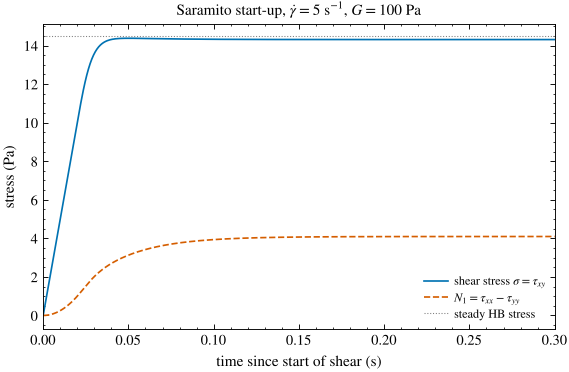

In [9]:
# (3) start-up of shear from rest, integrated in time (cross-check made for this notebook).
# D tau/Dt = (grad u) tau + tau (grad u)^T + G (2D - alpha tau); for simple shear this gives:
def startup_rhs(t, y):
    txx, txy, tyy, tzz = y
    a = alpha_of(y)
    return [2 * gd * txy - G_mod * a * txx,
            gd * tyy + G_mod * (gd - a * txy),
            -G_mod * a * tyy,
            -G_mod * a * tzz]

sol = solve_ivp(startup_rhs, [0, 4], [0, 0, 0, 0], method="LSODA", rtol=1e-10, atol=1e-12, dense_output=True)
t_plot = np.linspace(0, 0.3, 600)
txx_t, txy_t = sol.sol(t_plot)[0], sol.sol(t_plot)[1]
print(f"state at t = 4 s: sigma = {sol.y[1, -1]:.4f} Pa, N1 = {sol.y[0, -1]:.4f} Pa")
assert np.allclose(sol.y[:2, -1], [N1_closed, s_closed], rtol=1e-6)

fig, ax = plt.subplots(figsize=(6, 3.6))
ax.plot(t_plot, txy_t, color=C["blue"], label=r"shear stress $\sigma=\tau_{xy}$")
ax.plot(t_plot, txx_t, color=C["red"], ls="--", label=r"$N_1=\tau_{xx}-\tau_{yy}$")
ax.axhline(sigma_y + K * gd**n, color="0.5", lw=0.7, ls=":", label="steady HB stress")
ax.set(xlabel="time since start of shear (s)", ylabel="stress (Pa)", xlim=(0, 0.3),
       title=r"Saramito start-up, $\dot\gamma=5$ s$^{-1}$, $G=100$ Pa")
ax.legend(fontsize=8); plt.show()

The start-up shows the elastic loading ($\sigma\approx G\dot\gamma t$ at first), a small stress overshoot after yielding, and the approach to the steady state of Eq. (33), with a first normal-stress difference that the HB law cannot produce. The steady shear stress, 14.31 Pa, lies below the HB value 14.47 Pa.

### How far is the steady Saramito flow curve from HB?
The two curves differ at $O((\sigma/G)^2)$. Below we compute the relative stress difference at fixed rate for several moduli.

G =    30 Pa: relative difference at 1/s = 7.34e-02, times (G/sigma_y)^2 = 0.661
G =   100 Pa: relative difference at 1/s = 8.45e-03, times (G/sigma_y)^2 = 0.845
G =   300 Pa: relative difference at 1/s = 9.65e-04, times (G/sigma_y)^2 = 0.868
G =  1000 Pa: relative difference at 1/s = 8.71e-05, times (G/sigma_y)^2 = 0.871


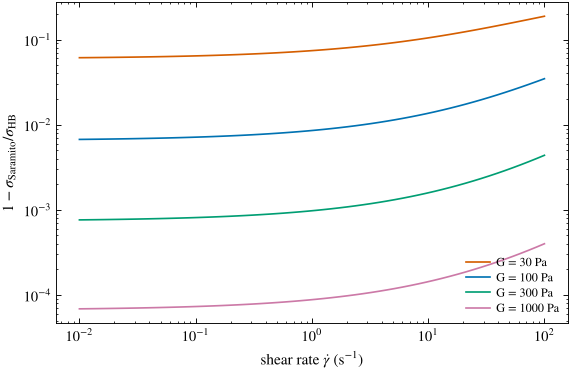

In [10]:
rates = np.logspace(-2, 2, 60)
fig, ax = plt.subplots(figsize=(6, 3.8))
for G, col in zip([30, 100, 300, 1000], [C["red"], C["blue"], C["green"], C["purple"]]):
    s_sar = np.array([brentq(lambda x: rate_saramito(x, G) - g, 0.5 * sigma_y, 1e3, xtol=1e-13) for g in rates])
    s_hb = sigma_y + K * rates**n
    rel = 1 - s_sar / s_hb
    ax.loglog(rates, rel, color=col, label=f"G = {G} Pa")
    # O((sigma/G)^2) scaling: rel * G^2 should be nearly independent of G when sigma/G is small
    print(f"G = {G:5d} Pa: relative difference at 1/s = {rel[np.argmin(abs(rates - 1))]:.2e}, "
          f"times (G/sigma_y)^2 = {rel[np.argmin(abs(rates - 1))] * (G / sigma_y)**2:.3f}")
ax.set(xlabel=r"shear rate $\dot\gamma$ (s$^{-1}$)", ylabel=r"$1-\sigma_{\rm Saramito}/\sigma_{\rm HB}$")
ax.legend(fontsize=8); plt.show()

Multiplying the difference by $(G/\sigma_y)^2$ collapses the values for large $G$: the departure scales as $(\sigma/G)^2$. When $\sigma_y/G\ll1$ (a small elastic yield strain) the steady Saramito curve is practically the HB curve, which supports using the elastic yield strain as a coordinate of HB applicability (Table XI of the article). Note also that steady EVP flows need not be unique; in Couette flow they can depend on the initial stress (Sec. VIII C).

## 6. A fixed-parameter test of the Saramito model

Write the Saramito prediction in the form used by de Cagny et al.: $N_1=2\sigma^2/G$ means $\psi_1=2/G$, and $N_2=0$ means $\psi_2=0$, **for every parameter set**. Two consequences follow without any fitting (Note S3 B, Sec. VIII C):
* matching the measured $\psi_1$ would require $G=2/\psi_1$, a modulus that an independent oscillatory measurement could confirm or reject;
* the measured $\psi_2/\psi_1$ is $-0.49$ to $-0.86$, whereas the upper-convected model predicts 0. This rejects the upper-convected variant whatever the value of $G$. A nonzero $N_2$ needs a different objective derivative (for example the Gordon–Schowalter form, which brings an extra parameter) or another ingredient.

In [11]:
test = pd.DataFrame({
    "G = 2/psi1 (Pa)": 2 / mat["psi1_Pa_inv"],
    "measured psi2/psi1": mat["psi2_over_psi1"],
    "UC Saramito psi2/psi1": 0.0,
})
# What the UC model with G = 2/psi1 implies for the yield invariant at sigma_y (N2 = 0), compared with the data (N2 < 0)
for name, m in mat.iterrows():
    G = 2 / m["psi1_Pa_inv"]; sy = m["sigma_y_Pa"]
    test.loc[name, "increase at sigma_y, UC model (%)"] = 100 * (sigma_d_saramito(sy, G) / sy - 1)
    test.loc[name, "increase at sigma_y, measured fits (%)"] = at_yield.loc[name, "increase at sigma_y (%)"]
print(test.round(3).to_string())
assert np.allclose(test["G = 2/psi1 (Pa)"].round(0), [627, 621, 669])

          G = 2/psi1 (Pa)  measured psi2/psi1  UC Saramito psi2/psi1  increase at sigma_y, UC model (%)  increase at sigma_y, measured fits (%)
material                                                                                                                                       
Emulsion          626.959              -0.727                    0.0                              0.485                                   0.389
Hair gel          621.118              -0.488                    0.0                              0.550                                   0.413
Carbopol          668.896              -0.863                    0.0                              0.637                                   0.562


The moduli required, 620–670 Pa, are plausible numbers that could be compared with the measured storage moduli. The upper-convected model, with $N_2=0$, would put the onset invariant about 0.5–0.6% above $\sigma$ at yield; the measured negative $N_2$ lowers that to 0.4–0.6%. Either way the onset shift is small. The decisive discrepancy is the sign and size of $N_2$: a model that matches the shear curve but not the normal stresses remains incomplete.

## Try it yourself

**Exercise 1 — when do normal stresses matter for the invariant?** For each material, find the shear stress at which $\sigma_d$ exceeds $\sigma$ by 5%.
*Hint:* with $N_i=\psi_i\sigma^2$, Eq. (S5) gives $\sigma_d/\sigma=\sqrt{1+\sigma^2(\psi_1^2+\psi_1\psi_2+\psi_2^2)/3}$; solve for $\sigma$.

**Exercise 2 — uniaxial extension of the HB law.** Build $\mathbf D={\rm diag}(-\dot\epsilon/2,-\dot\epsilon/2,\dot\epsilon)$ and the HB extra stress, and verify article Eq. (11): $\sigma_E=\tau_{zz}-\tau_{xx}=\sqrt3\,\sigma_y+3^{(n+1)/2}K\dot\epsilon^{\,n}$. Here the isotropic law does give a normal-stress difference. Why is this not a contradiction with Sec. 1?
*Hint:* $\dot\gamma=\sqrt{2\mathbf D:\mathbf D}=\sqrt3\,\dot\epsilon$.

**Exercise 3 — the Saramito onset.** For the three materials of Table SII, take $G=2/\psi_1$ and compute the shear stress at which the Saramito model starts to flow in steady shear. By how much is it below the HB intercept?
*Hint:* solve $\sigma\sqrt{1+4\sigma^2/(3G^2)}=\sigma_y$.

<details><summary>Solutions (click to expand)</summary>

1. $\sigma=\sqrt{3(1.05^2-1)/(\psi_1^2+\psi_1\psi_2+\psi_2^2)}$: about 194 Pa for the emulsion, 199 Pa for the hair gel and 198 Pa for the Carbopol gel, three to four times the yield stresses.
2. The code below reproduces Eq. (11) to machine precision. There is no contradiction: in extension $\mathbf D$ itself has unequal diagonal components, so the isotropic law transmits them to $\boldsymbol\tau$; in simple shear the diagonal of $\mathbf D$ is zero.
3. With $G=627$, 621 and 669 Pa the onset is 0.48%, 0.54% and 0.63% below $\sigma_y$ (about 0.26, 0.31 and 0.41 Pa), close to the estimate $2\sigma_y^2/(3G^2)$ = 0.49%, 0.55% and 0.64%.
</details>

In [12]:
# Optional solution code (uncomment to run)
# # 1
# for name, m in mat.iterrows():
#     p1, p2 = m["psi1_Pa_inv"], m["psi2_Pa_inv"]
#     print(name, np.sqrt(3 * (1.05**2 - 1) / (p1**2 + p1 * p2 + p2**2)))
# # 2
# eps_dot = 0.7
# D_ext = np.diag([-eps_dot / 2, -eps_dot / 2, eps_dot])
# g_ext = np.sqrt(2 * np.sum(D_ext * D_ext))
# tau_ext = (sigma_y / g_ext + K * g_ext ** (n - 1)) * 2 * D_ext
# print(tau_ext[2, 2] - tau_ext[0, 0], np.sqrt(3) * sigma_y + 3 ** ((n + 1) / 2) * K * eps_dot**n)
# # 3
# for name, m in mat.iterrows():
#     G, sy = 2 / m["psi1_Pa_inv"], m["sigma_y_Pa"]
#     s_on = brentq(lambda x: sigma_d_saramito(x, G) - sy, 0, sy)
#     print(name, round(G), s_on, 100 * (1 - s_on / sy), 100 * 2 * sy**2 / (3 * G**2))

## Key points
* An isotropic generalized Newtonian law, HB included, makes the extra stress proportional to $\mathbf D$; in simple shear the diagonal of $\mathbf D$ vanishes, so $N_1=N_2=0$. Normal stresses lie outside the baseline model.
* With normal-stress differences the von Mises magnitude is $\sigma_d^2=\sigma^2+(N_1^2+N_1N_2+N_2^2)/3$ (Eq. S5). For the three materials of de Cagny et al. (2019), $N_1\approx\sigma_y/5$ at yield but $\sigma_d$ exceeds $\sigma$ by only 0.4–0.6%: the onset criterion is barely affected, while normal-force observables are not negligible, and the effect grows like $\sigma^2$.
* The upper-convected Saramito model, Eq. (32), gives in steady shear $N_1=2\sigma^2/G$, $N_2=0$ and a flow curve that differs from HB at $O((\sigma/G)^2)$, Eq. (33); for $\sigma_y=10$ Pa, $K=2$ Pa s$^{0.5}$, $n=0.5$, $G=100$ Pa the stress at 5 s$^{-1}$ is 14.31 Pa against 14.47 Pa for HB.
* The measured $\psi_2/\psi_1=-0.49$ to $-0.86$ rejects the upper-convected variant for any $G$; matching $\psi_1$ needs $G=2/\psi_1\approx620$–670 Pa, which an independent modulus measurement can test.

## References

The review and its repository:
* Y. Wang (2026). A century of the Herschel–Bulkley model (1926–2026): Widespread use, community achievements, predictive capability, and engineering implications. Manuscript submitted to the *Journal of Rheology*; code and data: https://github.com/ktwyw/hb-centenary-review

* de Cagny, H., Fazilati, M., Habibi, M., Denn, M. M., and Bonn, D. (2019). The yield normal stress. *Journal of Rheology* **63**(2), 285–290. https://doi.org/10.1122/1.5063796
* Herschel, W. H., and Bulkley, R. (1926). Konsistenzmessungen von Gummi-Benzollösungen. *Kolloid-Zeitschrift* **39**(4), 291–300. https://doi.org/10.1007/bf01432034
* Hohenemser, K., and Prager, W. (1932). Über die Ansätze der Mechanik isotroper Kontinua. *ZAMM – Zeitschrift für Angewandte Mathematik und Mechanik* **12**(4), 216–226. https://doi.org/10.1002/zamm.19320120403
* Oldroyd, J. G. (1947). A rational formulation of the equations of plastic flow for a Bingham solid. *Mathematical Proceedings of the Cambridge Philosophical Society* **43**(1), 100–105. https://doi.org/10.1017/s0305004100023239
* Saramito, P. (2007). A new constitutive equation for elastoviscoplastic fluid flows. *Journal of Non-Newtonian Fluid Mechanics* **145**(1), 1–14. https://doi.org/10.1016/j.jnnfm.2007.04.004
* Saramito, P. (2009). A new elastoviscoplastic model based on the Herschel–Bulkley viscoplastic model. *Journal of Non-Newtonian Fluid Mechanics* **158**(1–3), 154–161. https://doi.org/10.1016/j.jnnfm.2008.12.001